# KMeans for Iris Dataset

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

In [2]:
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
import pandas as pd


### we will use sepal length and petal length for seperation.

In [52]:

iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target

# Select only important features
X = X[['sepal length (cm)', 'petal length (cm)']]

print(X.head())
print(X.shape)

   sepal length (cm)  petal length (cm)
0                5.1                1.4
1                4.9                1.4
2                4.7                1.3
3                4.6                1.5
4                5.0                1.4
(150, 2)


### visualize data

<Axes: xlabel='sepal length (cm)', ylabel='petal length (cm)'>

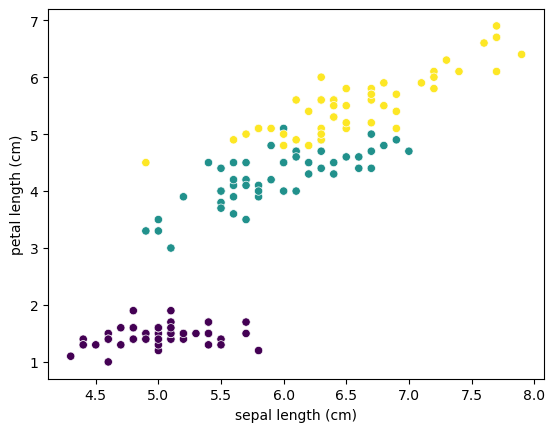

In [53]:
# sns.scatterplot(x=X[: , 0] , y= X[:, 1] ,marker=y) # gives error as dataframe slicing
sns.scatterplot(data=X , x='sepal length (cm)' , y='petal length (cm)' ,c=y)

In [54]:
from sklearn.preprocessing import StandardScaler

In [55]:
sc = StandardScaler()


X_scaled = sc.fit_transform(X)

In [15]:
X_scaled

array([[-9.00681170e-01,  1.01900435e+00, -1.34022653e+00,
        -1.31544430e+00],
       [-1.14301691e+00, -1.31979479e-01, -1.34022653e+00,
        -1.31544430e+00],
       [-1.38535265e+00,  3.28414053e-01, -1.39706395e+00,
        -1.31544430e+00],
       [-1.50652052e+00,  9.82172869e-02, -1.28338910e+00,
        -1.31544430e+00],
       [-1.02184904e+00,  1.24920112e+00, -1.34022653e+00,
        -1.31544430e+00],
       [-5.37177559e-01,  1.93979142e+00, -1.16971425e+00,
        -1.05217993e+00],
       [-1.50652052e+00,  7.88807586e-01, -1.34022653e+00,
        -1.18381211e+00],
       [-1.02184904e+00,  7.88807586e-01, -1.28338910e+00,
        -1.31544430e+00],
       [-1.74885626e+00, -3.62176246e-01, -1.34022653e+00,
        -1.31544430e+00],
       [-1.14301691e+00,  9.82172869e-02, -1.28338910e+00,
        -1.44707648e+00],
       [-5.37177559e-01,  1.47939788e+00, -1.28338910e+00,
        -1.31544430e+00],
       [-1.26418478e+00,  7.88807586e-01, -1.22655167e+00,
      

#### (Optional) Dimensionality reduction using PCA

### Elbow method

In [56]:

wcss = []


for k in range(1,11):
    kmean = KMeans(n_clusters=k , random_state=42)
    kmean.fit(X_scaled)
    wcss.append(kmean.inertia_)
wcss

[300.0,
 84.7207386219337,
 43.03469199603467,
 29.38665135838819,
 22.39598608015195,
 16.84719929046285,
 13.897240531466128,
 12.343723381195773,
 10.242756777006118,
 9.136055562037889]

<Axes: >

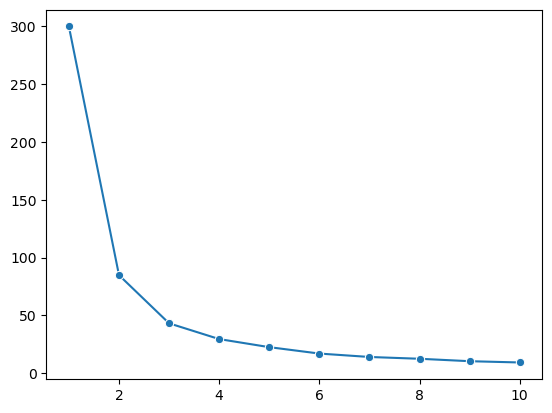

In [57]:
sns.lineplot(x=range(1,11) , y=wcss , marker='o')

- we can say 3 is good but yeas there is bend at 2 as well as we visualized earlier

### KMeans

In [58]:
kmeans = KMeans(n_clusters=3, random_state=42)
labels = kmeans.fit_predict(X_scaled)

<Axes: >

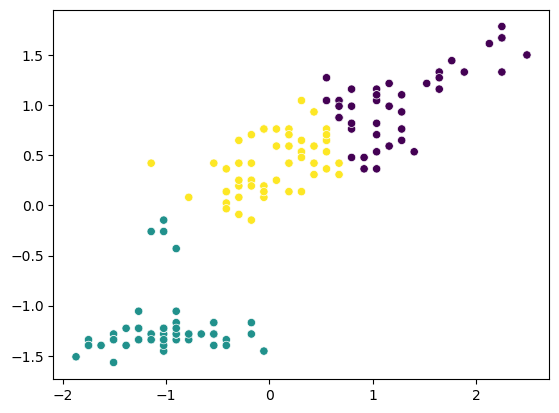

In [60]:
sns.scatterplot(x =X_scaled[:,0], y=X_scaled[:,1],c=labels)

### lets try using PCA 

In [61]:
X = iris.data


In [64]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

pca_data = pca.fit_transform(X)

In [65]:
pca_data

array([[-2.68412563,  0.31939725],
       [-2.71414169, -0.17700123],
       [-2.88899057, -0.14494943],
       [-2.74534286, -0.31829898],
       [-2.72871654,  0.32675451],
       [-2.28085963,  0.74133045],
       [-2.82053775, -0.08946138],
       [-2.62614497,  0.16338496],
       [-2.88638273, -0.57831175],
       [-2.6727558 , -0.11377425],
       [-2.50694709,  0.6450689 ],
       [-2.61275523,  0.01472994],
       [-2.78610927, -0.235112  ],
       [-3.22380374, -0.51139459],
       [-2.64475039,  1.17876464],
       [-2.38603903,  1.33806233],
       [-2.62352788,  0.81067951],
       [-2.64829671,  0.31184914],
       [-2.19982032,  0.87283904],
       [-2.5879864 ,  0.51356031],
       [-2.31025622,  0.39134594],
       [-2.54370523,  0.43299606],
       [-3.21593942,  0.13346807],
       [-2.30273318,  0.09870885],
       [-2.35575405, -0.03728186],
       [-2.50666891, -0.14601688],
       [-2.46882007,  0.13095149],
       [-2.56231991,  0.36771886],
       [-2.63953472,

In [68]:

wcss = []


for k in range(1,11):
    kmean = KMeans(n_clusters=k , random_state=42)
    kmean.fit(pca_data)
    wcss.append(kmean.inertia_)
wcss

[666.1659556405612,
 137.1553011281841,
 63.81994202200127,
 42.22517564743,
 35.60096738779262,
 28.248464076196736,
 24.707426163954892,
 17.9842815449628,
 16.207026352641055,
 14.939145863787745]

<Axes: >

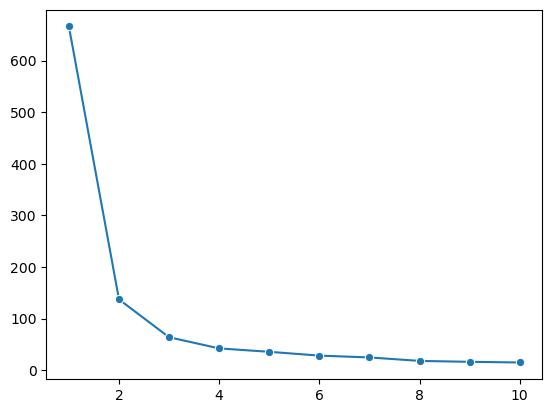

In [69]:
sns.lineplot(x=range(1,11) , y=wcss , marker='o')

In [70]:
kmeans = KMeans(n_clusters=3, random_state=42)
labels = kmeans.fit_predict(pca_data)

<Axes: >

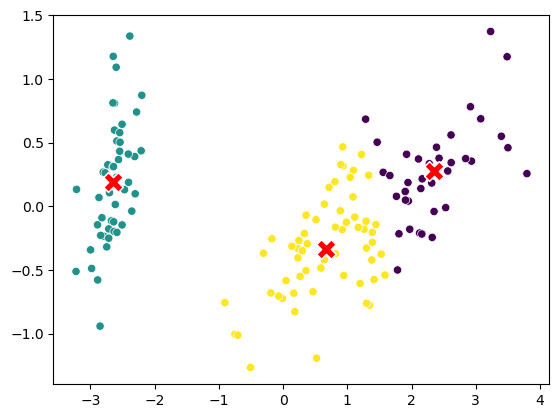

In [72]:
sns.scatterplot(x =pca_data[:,0], y=pca_data[:,1],c=labels)
sns.scatterplot(x=kmeans.cluster_centers_[:,0], y=kmeans.cluster_centers_[:,1], marker='X', s=200, color='red')